<a target="_blank" href="https://colab.research.google.com/github/TUIlmenauAMS/Videocoding/blob/main/LecturesJupterNotebooks/Lecture12/Lecture12.ipynb">
<img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/>
</a>

# <font color="#B85C38">Lecture 12: Quality Measurement</font>

*Video Coding · Prof. Gerald Schuller*

Assume, we have a video codec. How do we evaluate this codec, or compare it with other codecs? Especially if we use irrelevance reduction (properties of the eye), the best would be a subjective test, where we have several test viewers look at images under controlled conditions, and have them evaluate the decoded images or videos. This is called subjective quality measurement. Especially for small impairments, it is helpful to give the test viewers a comparison to the original, uncoded video, as can be seen in the following picture, where there is a switch between the original and the decoded video.

![Lecture12-1.PNG](https://github.com/TUIlmenauAMS/Videocoding/blob/main/LecturesJupterNotebooks/Lecture12/Img-Lecture12/Lecture12-1.PNG?raw=1)

**Fig.1** DSCQS testing system
(source: Richardson: “Video Codec Design”)

Using this system, the test viewers then evaluate the quality according to a scale, as in following picture:

![Lecture12-2.PNG](https://github.com/TUIlmenauAMS/Videocoding/blob/main/LecturesJupterNotebooks/Lecture12/Img-Lecture12/Lecture12-2.PNG?raw=1)

**Fig.2** DSCQS rating form
(source: Richardson: “Video Codec Design”)

Observe that we have items A and B. Often, one of the 2 is the original, and the other the item under test. In this way it can be tested if the test viewer recognized the original. A similar methodology can be found for perceptual testing of audio material. To measure small differences, it is useful to have trained test viewers.

This subjective measurement yields the most reliable results, because it involves the human eye, as the target for our application (as long as the eye is the intended viewer). The drawback of it is, that it is quite time consuming and expensive to conduct. To solve this problem, also objective measurements are used, measurements which can be done by using a computer or machine. The most well known and most widely used in the context of video coding is the so-called Peak-SNR or PSNR. If we compute the mean squared error between the original and the decoded video or image as MSE (the average of all squared differences of the pixels of original and decoded version), then the PSNR is computed as:

$$PSNR= 10\log_{10}(\frac{(2^n-1)^2}{MSE})$$

where n is the number of bits per pixel value (usually 8). Hence $(2^n-1)$represents the peak value in the image (usually 255), and hence the name “Peak” SNR (observe that we conduct this calculation per channel, i.e. for R,G,B or Y,Cb,Cr). The PSNR has the advantage, compared to the SNR, that it is independent of the internal representation of the image, meaning the number of bits per pixel (the SNR would change with the number of pixels).

**Advantage:** Very easy to compute.

**Disadvantage:**

a) We need the original (not always available)

b) Does not correlate well with human vision (it is only useful for instance to compare different versions of an algorithm, because its basic artifacts would not change)
The latter reason is the bigger problem, because quality comparison is its main objective. Consider for instance the following pictures:

![Lecture12-3.PNG](https://github.com/TUIlmenauAMS/Videocoding/blob/main/LecturesJupterNotebooks/Lecture12/Img-Lecture12/Lecture12-3.PNG?raw=1)

![Lecture12-4.PNG](https://github.com/TUIlmenauAMS/Videocoding/blob/main/LecturesJupterNotebooks/Lecture12/Img-Lecture12/Lecture12-4.PNG?raw=1) \
**Fig.3** Quality comparison of images

Observe that the image a) appears with a higher quality than image b), because there the faces are sharper. But the PSNR is higher for image b), saying that image b) should have a higher quality. This is because in image a) the larger background is unsharp. But the PSNR does not distinguish between areas which are important for the eye (faces), and areas which are unimportant (background).

For this reason there are works to improve objective (machine based) measurements to include properties of the eye, to make the resulting quality scores more similar to subjective measurements. One example is the so-called Structural Similarity Measurement (SSIM, or MSSIM, from Al Bovik et al.) which emphasises “structure”, meaning edges in images.

Its performance is illustrated in following images:

![Lecture12-5.PNG](https://github.com/TUIlmenauAMS/Videocoding/blob/main/LecturesJupterNotebooks/Lecture12/Img-Lecture12/Lecture12-5.PNG?raw=1)

**Fig.4** Comparison of “Boat” images with different types of distortions, all with MSE = 210. (a) Original image (8 bits/pixel; cropped from 512 x 512 to 256 x 256 for visibility). (b) Contrast-stretched image, MSSIM = 0,9168.(c) Mean-shifted image, MSSIM = 0,9900. (d) JPEG compressed image, MSSIM = 0,6949. (e) Blurred image, MSSIM = 0,7052. (f) Salt-pepper impulsive noise contaminated image, MSSIM = 0,7748.

(source: Wan, Bovik, Sheikh: “Image Quality Assessment: From Error Visibility to Structural Similarity”, IEEE Trans. on Image Processing, April 2004.)

**More Image Quality Measures**

There are more image quality measures, among them also neural network based measures. Examples are:
VMAF, DISTS, LPIPS

For an overview, read:
https://www.elecard.com/page/article_interpretation_of_metrics

For VMAF, read:
https://de.wikipedia.org/wiki/Video_Multi-Method_Assessment_Fusion

For LPIPS, read:
https://github.com/richzhang/PerceptualSimilarity

For LPIPS: This is a neural network, trained on visual difference between original and distorted version. No distortion means value Zero.
Observe that it needs a long time to install, due to the large number of coefficients for its neural network.

## <font color="#B85C38">Implementation, example in ffmpeg:</font>

In [1]:
!apt install ffmpeg

Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
ffmpeg is already the newest version (7:4.4.2-0ubuntu0.22.04.1).
0 upgraded, 0 newly installed, 0 to remove and 3 not upgraded.


Cloning into 'Videocoding'...
remote: Enumerating objects: 800, done.
remote: Counting objects: 100% (130/130), done.
remote: Compressing objects: 100% (124/124), done.
remote: Total 800 (delta 59), reused 0 (delta 0), pack-reused 670 (from 1)
Receiving objects: 100% (800/800), 77.04 MiB | 28.92 MiB/s, done.
Resolving deltas: 100% (364/364), done.
Original:


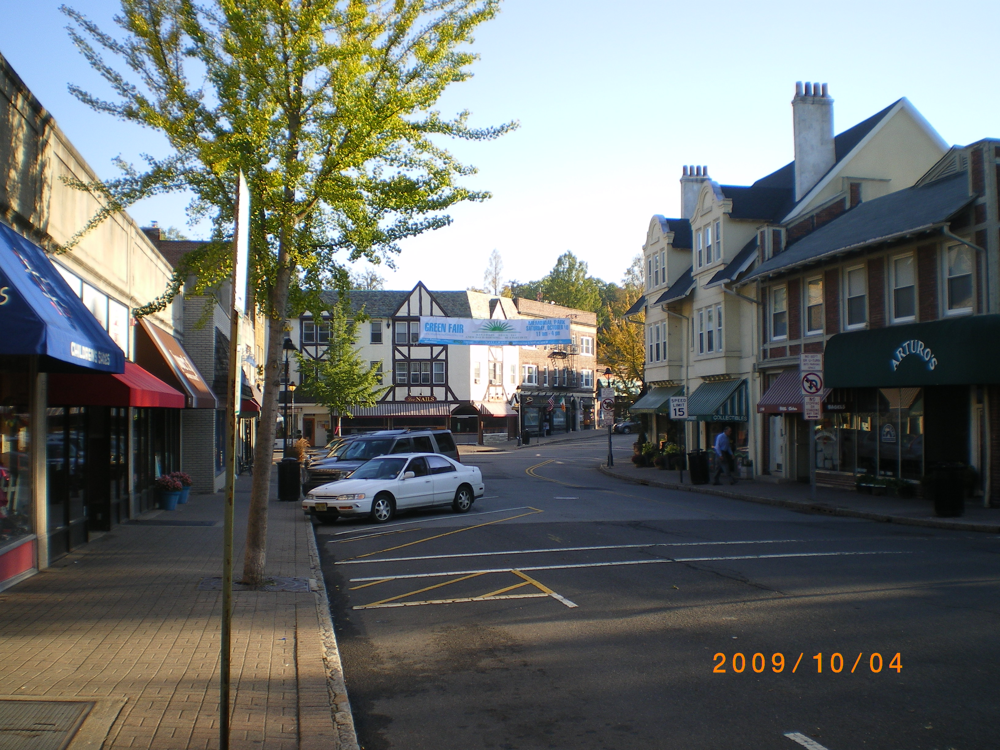

In [2]:
!git clone https://github.com/TUIlmenauAMS/Videocoding
import cv2
from google.colab.patches import cv2_imshow

photo=cv2.imread('/content/Videocoding/LecturesJupterNotebooks/IMGP1690.JPG');
print("Original:")
cv2_imshow(photo)


Distorted:


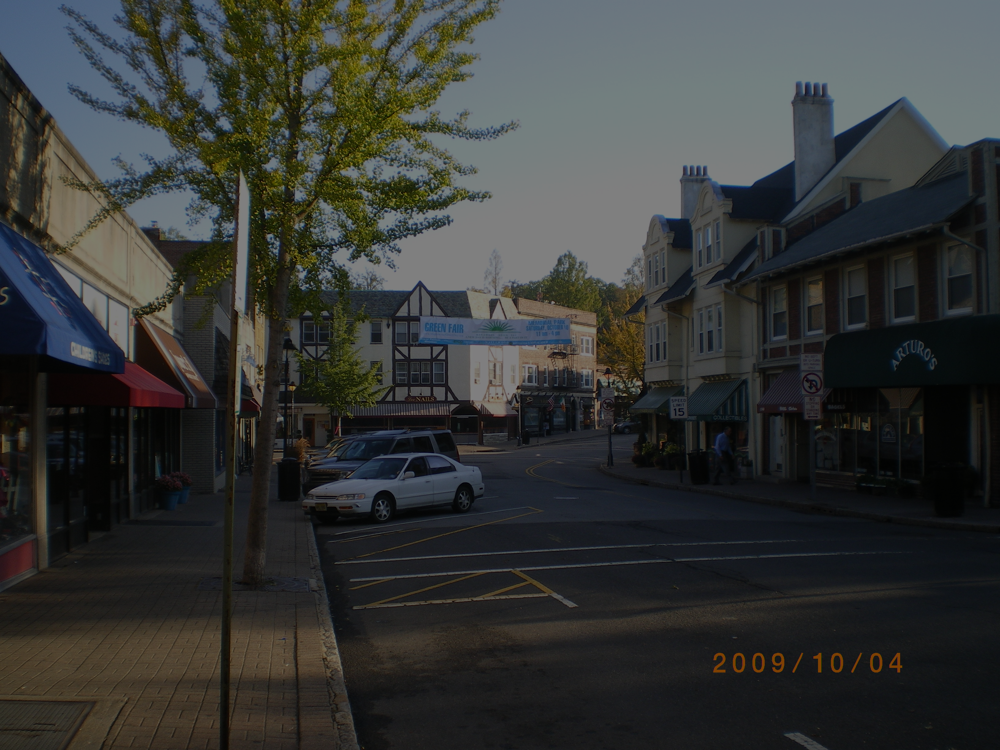

In [5]:
photodist=0.5*photo #less contrast distortion
cv2.imwrite('distorted.jpg', photodist)
print("Distorted:")
cv2_imshow(photodist)


In [7]:
print("PSNR value, higher is better (infinity for perfect similarity):")
!ffmpeg -i '/content/Videocoding/LecturesJupterNotebooks/IMGP1690.JPG' -i 'distorted.jpg' -filter_complex "psnr" -f null /dev/null

PSNR value, higher is better (infinity for perfect similarity):
ffmpeg version 4.4.2-0ubuntu0.22.04.1 Copyright (c) 2000-2021 the FFmpeg developers
  built with gcc 11 (Ubuntu 11.2.0-19ubuntu1)
  configuration: --prefix=/usr --extra-version=0ubuntu0.22.04.1 --toolchain=hardened --libdir=/usr/lib/x86_64-linux-gnu --incdir=/usr/include/x86_64-linux-gnu --arch=amd64 --enable-gpl --disable-stripping --enable-gnutls --enable-ladspa --enable-libaom --enable-libass --enable-libbluray --enable-libbs2b --enable-libcaca --enable-libcdio --enable-libcodec2 --enable-libdav1d --enable-libflite --enable-libfontconfig --enable-libfreetype --enable-libfribidi --enable-libgme --enable-libgsm --enable-libjack --enable-libmp3lame --enable-libmysofa --enable-libopenjpeg --enable-libopenmpt --enable-libopus --enable-libpulse --enable-librabbitmq --enable-librubberband --enable-libshine --enable-libsnappy --enable-libsoxr --enable-libspeex --enable-libsrt --enable-libssh --enable-libtheora --enable-libtwola

PSNR: 14 dB, which is quite low (for instance 40 dB would be a good value).

## <font color="#B85C38">SSIM Value (1.0 is best):</font>

In [8]:
print("ssim value, 1.0 means perfect similarity:")
!ffmpeg -i '/content/Videocoding/LecturesJupterNotebooks/IMGP1690.JPG' -i 'distorted.jpg' -filter_complex "ssim" -f null /dev/null

ssim value, 1.0 means perfect similarity:
ffmpeg version 4.4.2-0ubuntu0.22.04.1 Copyright (c) 2000-2021 the FFmpeg developers
  built with gcc 11 (Ubuntu 11.2.0-19ubuntu1)
  configuration: --prefix=/usr --extra-version=0ubuntu0.22.04.1 --toolchain=hardened --libdir=/usr/lib/x86_64-linux-gnu --incdir=/usr/include/x86_64-linux-gnu --arch=amd64 --enable-gpl --disable-stripping --enable-gnutls --enable-ladspa --enable-libaom --enable-libass --enable-libbluray --enable-libbs2b --enable-libcaca --enable-libcdio --enable-libcodec2 --enable-libdav1d --enable-libflite --enable-libfontconfig --enable-libfreetype --enable-libfribidi --enable-libgme --enable-libgsm --enable-libjack --enable-libmp3lame --enable-libmysofa --enable-libopenjpeg --enable-libopenmpt --enable-libopus --enable-libpulse --enable-librabbitmq --enable-librubberband --enable-libshine --enable-libsnappy --enable-libsoxr --enable-libspeex --enable-libsrt --enable-libssh --enable-libtheora --enable-libtwolame --enable-libvidstab

SSIM: 0.8, which indicates a relatively good visual quality (probably truer than PSNR).

## <font color="#B85C38">Python example for using LPIPS (0.0 is best):</font>

In [9]:
#!git clone https://github.com/TUIlmenauAMS/Videocoding
!pip install lpips
import cv2
import numpy as np
import torch
import lpips
from google.colab.patches import cv2_imshow

def convtolpips(photo):
    #takes photo from cv2 and converts it for LPIPS
    photoRGB=photo[:,:,::-1] #convert from BGR to RGB
    phototranspose=np.transpose(photoRGB, (2,0,1))
    #primary color index first
    photolpips=torch.from_numpy((
    phototranspose/255).astype(np.float32))
    return  photolpips

photo=cv2.imread('/content/Videocoding/LecturesJupterNotebooks/IMGP1690.JPG');
#print("Original:")
#cv2_imshow(photo)
photodist=0.5*photo #less contrast distortion
#print("Distorted:")
#cv2_imshow(photodist)
photolpips=convtolpips(photo)
photodistlpips=convtolpips(photodist)

loss_fn_alex = lpips.LPIPS(net='alex')
#loss_fn_vgg = lpips.LPIPS(net='vgg')
#loss_fn_vgg(photolpips, photodistlpips)
loss=loss_fn_alex (photolpips, photodistlpips)
print("--------------------")
print("\nLPIPS loss, most similarity is for value 0, = ", loss)

Setting up [LPIPS] perceptual loss: trunk [alex], v[0.1], spatial [off]


/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=AlexNet_Weights.IMAGENET1K_V1`. You can also use `weights=AlexNet_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Loading model from: /usr/local/lib/python3.12/dist-packages/lpips/weights/v0.1/alex.pth
--------------------

LPIPS loss, most similarity is for value 0, =  tensor([[[[0.1260]]]], grad_fn=<AddBackward0>)


LPIPS value: 0.12, which also indicates a relatively good visual quality.

## <font color="#B85C38">Further Literature:</font>

- IEEE Transactions on Image Processing, vol. 9, no. 4, pp. 636-650, Apr. 2000  
  “Image Quality Assessment Based on a Degradation Model”  
  Niranjan Damera-Venkata, and Thomas D. Kite, Wilson S. Geisler, Brian L. Evans, and Alan C. Bovik.

- IEEE International Conference on Acoustics, Speech, & Signal Processing, May 2002  
  “Why is Image Quality Assessment So Difficult?”  
  Zhou Wang1, Alan C. Bovik1 and Ligang Lu2.

The area of improved objective measurements is still an active research area. All available on ieeexplore.ieee.org within the network of the TU Ilmenau! (Try it for the  paper of Al Bovik above).

Future coders often deliver higher resolution at lower bit rates, meaning we have fewer bits per pixel. This means we need more sophisticated models of vision (at least implied) in those coders to obtain a good perceptual quality. This means we also need more sophisticated models of vision for our objective measurement systems.

## <font color="#B85C38">Standards for Representing Digital Video</font>

The first digital standards were derived from the analog TV standards (from: Richardson, “Video Codec Design”):

**Table 1** ITU-R BT.601-5 parameters

![Lecture12-6.PNG](https://github.com/TUIlmenauAMS/Videocoding/blob/main/LecturesJupterNotebooks/Lecture12/Img-Lecture12/Lecture12-6.PNG?raw=1)

This then leads to the following standards:

**Table 2** Intermediate formats

![Lecture12-7.PNG](https://github.com/TUIlmenauAMS/Videocoding/blob/main/LecturesJupterNotebooks/Lecture12/Img-Lecture12/Lecture12-7.PNG?raw=1)

The **Common Interchange Format** (CIF) is a widely used format for digital video. 4CIF has a resolution of 4 times the number of pixels of CIF, and has a resolution similar to standard definition TV.